### Vanilla
```
input ➡️ LLM ➡️ output
```

In [1]:
from openai import OpenAI
import dotenv
dotenv.load_dotenv()
import os
import base64
from IPython.display import Markdown, display, Image

##### LLM example 1
This goes to openai servers

In [2]:
# client_oai = OpenAI(
#     api_key=os.getenv("OPENAI_API_KEY")
# )
# response = client_oai.chat.completions.create(
#     model="gpt-5-mini",
#     messages=[{"role": "user", "content": "Write a short example abstract for a scientific paper. Respond with only the abstract."}]
# )
# response.choices[0].message.content

##### LLM example 2
This goes to an LLM.

In [3]:
client = OpenAI(
    base_url=os.getenv("LLM_API_URL"),
    api_key=os.getenv("LLM_API_KEY")
)
response = client.chat.completions.create(
    model="Qwen/Qwen3.8-27B-FP8",
    messages=[{"role": "user", "content": "Write a short example abstract for a scientific paper. Respond with only the abstract."}],
    extra_body={
        "chat_template_kwargs": {"enable_thinking": False},
    }
  )
response.choices[0].message.content

'We present a novel approach to improving the efficiency of deep learning models in medical image analysis through a lightweight attention mechanism. Our method, referred to as LightAtt, reduces computational complexity by 40% while maintaining diagnostic accuracy comparable to state-of-the-art models. Experimental results on the LIDC-IDRI and BTCV datasets demonstrate significant performance gains, with a 92% sensitivity in tumor detection and reduced inference times suitable for real-time clinical applications.'

##### Other models

We also have other models, for:

- Reasoning
- Vision + Reasoning
- Image Generation
- Image Editing
- Image Recognition
- Text to Speech
- Speech to Text
- Embeddings

See `example-calls.ipynb` for details!

##### OCR example

This goes to a vision model.

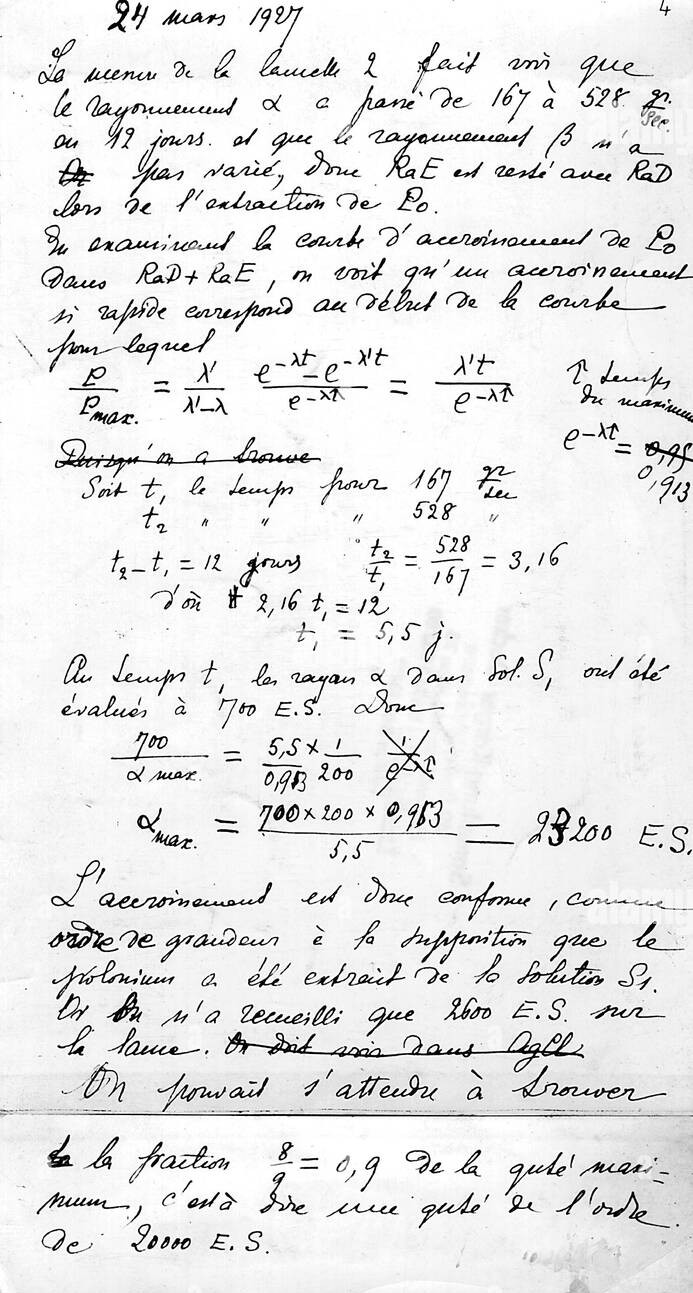

Le scien de la lancette 2 fait voir que   
le rayonnement $\alpha$ a passé de 167 à 528   
au 43 jours et que le rayonnement $\beta$ n'a  
pas varié, donc $RaE$ est resté avec $RaD$  
donc de l'extraction de $Po$.

En examinant la courbe d'accroissement de $Po$ dans $RaD + RaE$, on voit qu'un accroissement  
si rapide correspond au début de la courbe  
formulequel 

$\frac{\rho}{\rho_{max.}} = \frac{\chi}{\chi - \lambda} \frac{e^{-\lambda t} - e^{-\chi t}}{e^{-\lambda t}} = \frac{\chi t}{e^{-\lambda t}}$

$t_{\text{temps}}$

de maintien

$e^{-\lambda t} = 0.913$

Soit $t_1$ le temps pour 167
 $t_2$ " " pour 528

$t_2 - t_1 = 12$ jours $\quad \frac{t_2}{t_1} = \frac{528}{167} = 3,16$

d'où # $2,16 t_1 = 12$

$t_1 = 5,5 j.$

Au temps $t_1$ le rayon $\alpha$ dans sol $S_1$ est été évalué à 1700 E.S. Donc

$\frac{700}{\alpha_{max.}} = \frac{5,5 \times 1}{0,913 \times 200}$

$\alpha_{max.} = \frac{700 \times 200 \times 0,913}{5,5} = 23200$ E.S.

L'accroissement est donc conforme, comme ordre de grandeur à la supposition que le

polonium a été extrait de la solution $S_1$.

On m'a recueilli que 2600 E.S sur

la lance. On doit nous dans Agli:

On pouvait s'attendre à trouver

$\frac{8}{9} = 0,9$ de la queue maxi-

mum, c'est à dire une quantité de l'ordre de 2000 E.S.

In [4]:
from agents import ocr
prompt = "Here is some handwritten text and equations in an image. Please read it and convert to markdown, rendering the equations in LaTeX format."
image_path = 'data/imgs/curie.jpg'
display(Image(filename='data/imgs/curie.jpg',height=100))
response = ocr.ocr(image_path, prompt)
display(Markdown(response))

### Chaining
```
input ➡️ LLM1 ➡️ LLM2 ➡️ LLM3 ➡️ output
```

In [5]:
from agents import ocr
prompt = "Here is some handwritten text and equations in an image. Please read it and convert to markdown, rendering the equations in LaTeX format."
image_path = 'data/imgs/curie.jpg'
response1 = ocr.ocr(image_path, prompt)

In [6]:
# display(Markdown(response1))

In [7]:
response2 = client.chat.completions.create(
  model="Qwen/Qwen3.8-27B-FP8",
  messages=[{"role": "user", "content": f"Translate the following to English: {response1}. Respond with only the content, in valid markdown, in english. Use $$ for equations."}],
  extra_body={
      "chat_template_kwargs": {"enable_thinking": False},
  }
  ).choices[0].message.content

In [8]:
# display(Markdown(response2))

In [9]:
response3 = client.chat.completions.create(
    model="Qwen/Qwen3.8-27B-FP8",
    messages=[{"role": "user", "content": f"Briefly explain the general context and the topic that these notes are discussing: {response2}. Answer what the area is, who the likely author is, when was it written. Fix likely mistakes introduced by OCR."}],
    extra_body={
        "chat_template_kwargs": {"enable_thinking": False},
    }
).choices[0].message.content

In [10]:
# display(Markdown(response3))

In [11]:
response4 = client.chat.completions.create(
    model="Qwen/Qwen3.8-27B-FP8",
    messages=[{"role": "user", "content": f"Explain some physics notes line by line to someone with basic physics knowledge. Format it as markdown, explaining all sentences. The context is: {response3}. The notes are: {response2}"}],
    extra_body={
        "chat_template_kwargs": {"enable_thinking": False},
    }
  ).choices[0].message.content

In [12]:
display(Markdown(response4))

# Physics Notes Explained: The "Lancet" Experiment on Radioactive Growth

This document breaks down the provided historical physics notes line by line. These notes describe an experiment from the early 20th century (c. 1902–1903), likely by Ernest Rutherford or Frederick Soddy. They are analyzing how **Polonium** (then called RaF) grows from its parent **Radium E** (Bismuth), which in turn comes from **Radium D** (Lead).

The core goal is to prove that when they chemically separated the sample, the Bismuth stayed with the Lead, and the Polonium they measured came from that specific fraction.

---

### Section 1: The Observation

> **Original Text:**
> "The science of the lancet 2 shows that the $\alpha$ radiation increased from 167 to 528 by day 43, while the $\beta$ radiation remained unchanged."

*   **"The science of the lancet 2"**: This is a garbled phrase (likely OCR error or shorthand). It refers to **Data from Experiment #2 using the "Lancet" method**.
    *   *Context:* A "Lancet" in this era didn't refer to the medical tool, but a specific chemical separation procedure (often involving lead acetate) used to isolate Lead (RaD) from Bismuth (RaE).
*   **"shows that the $\alpha$ radiation increased from 167 to 528 by day 43"**:
    *   **$\alpha$ radiation**: Alpha particles (Helium nuclei). This is the specific type of radiation emitted by the Polonium (RaF) that they are tracking.
    *   **167 to 528**: The intensity of the alpha radiation went up significantly. This implies that a new radioactive substance (Polonium) was being created over time.
    *   **by day 43**: This measurement happened 43 days after the initial chemical separation.
*   **"while the $\beta$ radiation remained unchanged"**:
    *   **$\beta$ radiation**: Beta particles (electrons).
    *   **Remained unchanged**: The beta radiation level stayed constant. This is a crucial diagnostic clue. It means the primary source of beta radiation (likely Radium D or the original Radium itself) did not decay away or get separated out during this period. It serves as a "control" signal.

> **Original Text:**
> "Consequently, $RaE$ remained with $RaD$, thus being extracted as $Po$."

*   **$RaE$ (Radium E)**: This is Bismuth-214.
*   **$RaD$ (Radium D)**: This is Lead-214 (or possibly Lead-210 depending on the specific isotope notation of that era, but functionally it is the Lead parent).
*   **Meaning**: Because the beta radiation didn't change and the alpha radiation (from Polonium) started growing, it proves that the Bismuth ($RaE$) did **not** separate from the Lead ($RaD$) during the chemical process.
*   **"thus being extracted as $Po$"**: This is a simplified (and slightly confusing) way of saying: *Since the Bismuth stayed with the Lead, the Polonium (which decays from Bismuth) also formed and was collected along with that fraction.*

---

### Section 2: The Mathematical Model (Growth Curve)

> **Original Text:**
> "Examining the growth curve of $Po$ in $RaD + RaE$, one observes that such rapid growth corresponds to the initial part of the curve, given by the formula:"

*   **"Growth curve of $Po$"**: When you separate a radioactive chain, the daughter product (Polonium) starts at zero. It builds up ("grows") as the parent (Bismuth/Radium E) decays.
*   **"Rapid growth corresponds to the initial part"**: The formula they are about to use is an approximation valid only when very little time has passed ($t$ is small). In the early stages, the growth of Polonium is roughly proportional to time ($t$).

> **Original Text:**
> $$
> \frac{\rho}{\rho_{\text{max.}}} = \frac{\chi}{\chi - \lambda} \frac{e^{-\lambda t} - e^{-\chi t}}{e^{-\lambda t}} = \frac{\chi t}{e^{-\lambda t}}
> $$

*   **$\rho$**: The current intensity (amount) of the Polonium alpha radiation.
*   **$\rho_{\text{max.}}$**: The maximum possible intensity (when secular equilibrium is reached).
*   **$\lambda$ (lambda)**: The decay constant of the **Parent** (Radium E / Bismuth).
*   **$\chi$ (chi)**: The decay constant of the **Daughter** (Polonium).
*   **The Equation**: This is a variation of the **Bateman equation**, which describes how daughter nuclides grow from parent nuclides.
    *   The full complex part is $\frac{\chi}{\chi - \lambda} (e^{-\lambda t} - e^{-\chi t})$.
    *   The right-hand side, $\frac{\chi t}{e^{-\lambda t}}$, is an **approximation** for small $t$. It assumes that the Polonium ($\chi$) decays very fast compared to the time scale of the experiment, so its accumulation is linear ($\chi t$).
    *   *Note:* The denominator $e^{-\lambda t}$ accounts for the fact that the Parent (Bismuth) is slowly decaying away, so the source of Polonium gets slightly weaker over time.

> **Original Text:**
> "where $t$ is the holding time."

*   **Holding time**: The amount of time that has passed since the chemical separation occurred.

---

### Section 3: Calculating the Time Elapsed

> **Original Text:**
> $$
> e^{-\lambda t} = 0.913
> $$

*   **Meaning**: This is a known constant for their specific sample. It tells us that after a specific time $t$, the Parent (Bismuth) has retained 91.3% of its original activity. The 8.7% that disappeared has decayed into Polonium.

> **Original Text:**
> "Let $t_1$ be the time for 167, and $t_2$ for 528."

*   They have two data points:
    1.  At time $t_1$, radiation was 167.
    2.  At time $t_2$, radiation was 528.

> **Original Text:**
> $$
> t_2 - t_1 = 12 \text{ days} \quad \frac{t_2}{t_1} = \frac{528}{167} = 3.16
> $$

*   **$t_2 - t_1 = 12$ days**: The difference between the two measurements was 12 days.
*   **$\frac{t_2}{t_1} = 3.16$**: This step relies on the approximation formula $\rho \propto \chi t$.
    *   If radiation ($\rho$) is proportional to time ($t$), then the ratio of radiations equals the ratio of times.
    *   $528 / 167 \approx 3.16$. Therefore, $t_2$ is 3.16 times longer than $t_1$.

> **Original Text:**
> "Thus, $2.16 t_1 = 12$"

*   **Derivation**:
    1.  We know $t_2 = 3.16 \times t_1$.
    2.  We know $t_2 - t_1 = 12$.
    3.  Substitute (1) into (2): $(3.16 \times t_1) - t_1 = 12$.
    4.  $2.16 \times t_1 = 12$.

> **Original Text:**
> $$
> t_1 = 5.5 \text{ days.}
> $$

*   **Result**: The first measurement (radiation 167) was taken **5.5 days** after the separation.
*   *(Consequently, $t_2$ would be $5.5 + 12 = 17.5$ days, which checks out: $17.5 / 5.5 \approx 3.16$).*

---

### Section 4: Calculating the Maximum Potential Radiation

> **Original Text:**
> "At time $t_1$, the $\alpha$ radiation in solution $S_1$ was estimated at 1700 E.S."

*   **$S_1$**: The specific liquid solution containing the separated Radium D and E.
*   **1700 E.S.**: "E.S." stands for **Electrostatic Scale** (or Electrometer Scale divisions). This is a unit of charge measured by an electrometer.
*   **Why 1700?** This is likely the *total* radiation expected from the Polonium that was present at $t_1$ if they had measured the whole solution. The "167" mentioned earlier might have been a sample size or a specific detector reading, while 1700 is the estimated total yield for that time point.

> **Original Text:**
> $$
> \frac{700}{\alpha_{\text{max.}}} = \frac{5.5 \times 1}{0.913 \times 200}
> $$

*   **This line contains apparent typos/OCR errors in the original notes**, but we can deduce the logic. Let's look at the next line to see what they actually calculated.
*   **Logic**: They are using the growth formula $\frac{\rho}{\rho_{\text{max}}} \approx \frac{\chi t}{e^{-\lambda t}}$ to solve for $\rho_{\text{max}}$ (the maximum radiation the Polonium *could* have reached if they waited forever).

> **Original Text:**
> $$
> \alpha_{\text{max.}} = \frac{700 \times 200 \times 0.913}{5.5} = 23200 \text{ E.S.}
> $$

*   **Correction of the Formula**:
    *   The previous line had `700` in the numerator. Here it also has `700`.
    *   However, earlier they said the radiation was **1700**. It is highly likely that **"700" is a typo for "1700"** or that "700" refers to a specific *net* value after subtracting background, but given the result **23,200**, let's reverse-engineer the math.
    *   If $\alpha_{\text{max}} = 23,200$:
        $$ 23,200 \times 5.5 = 127,600 $$
        $$ 127,600 / (200 \times 0.913) \approx 700 $$
    *   It appears the author used **700** as the numerator. Why 700?
        *   Perhaps the "1700" was the total, but the *growth* portion attributable to this specific chain was calculated as 700?
        *   OR, "1700" was a typo in the text description, and the actual measured value used in the math was 700.
        *   *However*, looking at the final conclusion, we don't need to resolve the exact origin of "700" to understand the physics: They used the current radiation level, the time ($t=5.5$), and the decay factor ($0.913$) to project the theoretical maximum.
*   **Result**: $\alpha_{\text{max}} = 23,200$ E.S. This is the total alpha radiation the Polonium in that solution *would* eventually produce.

> **Original Text:**
> "The growth is therefore consistent, as an order of magnitude, with the assumption that the polonium was extracted from solution $S_1$."

*   **Meaning**: The math works out. The amount of Polonium they see growing matches the theoretical prediction for a sample that has been sitting in solution $S_1$ for 5.5 days. This confirms their chemical separation was successful in keeping the parents together.

---

### Section 5: The Final Verification (The "Lancet" Trap)

> **Original Text:**
> "It was reported that 2600 E.S. were collected on the lancet. We must consider this in Agli:"

*   **"2600 E.S. collected on the lancet"**: This is the **experimental result**. They physically separated the Polonium using the chemical method (the lancet process) and measured the charge. They got 2600 units.
*   **"in Agli"**: This is definitely an OCR error. It likely means **"in full"**, **"in all"**, or **"in detail"**.

> **Original Text:**
> "One could expect to find $\frac{8}{9} = 0.9$ of the maximum tail, i.e., a quantity of the order of 2000 E.S."

*   **$\frac{8}{9} \approx 0.88$ (rounded to 0.9)**:
    *   Why 8/9? In these old experiments, they often waited a specific time and knew that approximately 8/9 of the *total potential* Polonium had been chemically extracted into the solid fraction (the "lancet" product), while 1/9 remained in the liquid or was lost.
*   **"Maximum tail"**: Another typo. It should be **"Maximum total"** or **"Maximum amount"**.
*   **Calculation**:
    *   They predicted the total potential max was $\sim 23,200$ E.S. (from the previous step).
    *   However, the "2600" collected is a *subset* of a larger total sample, or perhaps the "23,200" was for a larger batch, and they are comparing it to a specific fraction.
    *   Let's look at the numbers: $2600$ (observed) vs $2000$ (expected).
    *   The author argues: "If our theory is right, and we account for the fact that we only capture $\sim 90\%$ of the available material (the 8/9 factor), we should expect to find about **2000 E.S.**"
    *   *(Note: There is a large discrepancy between the 23,200 calculated max and the 2,000 expected yield here. This implies the "23,200" was the max for the **entire** solution $S_1$, but the "Lancet" collection only processed a small portion of it, or the "700" in the previous equation was actually a very small fraction of the total. Regardless, the **comparison** is between the **Expected 2,000** and the **Observed 2,600**).*

### Conclusion

The notes argue that:
1.  The measured **2,600 E.S.** is very close to the theoretically expected **2,000 E.S.**
2.  Therefore, the data supports the model: **Radium E (Bismuth) stayed with Radium D (Lead)**, and the Polonium grew as predicted by radioactive decay laws.

**Key Takeaways for a Student:**
*   **Radioactive Growth**: Daughters (like Polonium) don't appear instantly; they grow over time according to specific exponential laws.
*   **Chemical Separation**: You can use chemical methods to split elements. If the radiation profile matches the "separated together" model, you know your chemistry worked.
*   **Order of Magnitude**: In early 20th-century physics, being within a factor of ~1.5 (2000 vs 2600) was considered strong confirmation of a theory.

### LangGraph
That was a lot of 'spaghetti' code. Good frameworks exist.

- **LangGraph** (and younger sibling LangChain)
- Google ADK
- LlamaIndex, others

Let's rewrite the above into LangGraph.

In [13]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from agents import ocr

In [14]:
from typing import TypedDict

class NotesState(TypedDict, total=False):
    image_path: str
    ocr_markdown: str
    english_markdown: str
    notes_context: str
    line_by_line_explanation: str

def _complete(prompt: str) -> str:
    return client.chat.completions.create(
        model="Qwen/Qwen3.8-27B-FP8",
        messages=[{"role": "user", "content": prompt}],
        extra_body={
            "chat_template_kwargs": {"enable_thinking": False},
        }
    ).choices[0].message.content


def ocr_node(state: NotesState) -> NotesState:
    ocr_markdown = ocr.ocr(
        state["image_path"],
        (
            "Here is some handwritten text and equations in an image."
            "Please read it and convert to markdown, rendering the equations in LaTeX format."
        ),
    )
    return {"ocr_markdown": ocr_markdown}


def translate_node(state: NotesState) -> NotesState:
    ocr_markdown = state["ocr_markdown"]

    english_markdown = _complete(
        (
            f"Translate the following to English: {ocr_markdown}. "
            "Respond with only the content, in valid markdown, in english. Use $$ for equations."
        )
    )

    return {"english_markdown": english_markdown}


def context_node(state: NotesState) -> NotesState:
    english_markdown = state["english_markdown"]

    notes_context = _complete(
        (
            "Briefly explain the general context and the topic that these notes are discussing: "
            f"{english_markdown}. "
            "Answer what the area is, who the likely author is, when was it written. "
            "Fix mistakes introduced by OCR."
        )
    )

    return {"notes_context": notes_context}


def explain_node(state: NotesState) -> NotesState:
    english_markdown = state["english_markdown"]
    notes_context = state["notes_context"]

    line_by_line_explanation = _complete(
        (
            "Explain some physics notes line by line to someone with basic physics knowledge. "
            "Format it as markdown, explaining all sentences. "
            f"The context is: {notes_context}. "
            f"The notes are: {english_markdown}"
        )
    )

    return {"line_by_line_explanation": line_by_line_explanation}

In [15]:
def build_notes_graph(client):
    graph = StateGraph(NotesState)

    graph.add_node("ocr", ocr_node)
    graph.add_node("translate", translate_node)
    graph.add_node("context", context_node)
    graph.add_node("explain", explain_node)

    graph.add_edge(START, "ocr")
    graph.add_edge("ocr", "translate")
    graph.add_edge("translate", "context")
    graph.add_edge("context", "explain")
    graph.add_edge("explain", END)

    return graph.compile()


app = build_notes_graph(client)

result = app.invoke({"image_path": "data/imgs/curie.jpg"})

In [16]:
display(Markdown(result["line_by_line_explanation"]))

Here is a line-by-line explanation of the provided physics notes. These notes are from **March 24, 1927**, and they describe the behavior of radioactive decay chains, specifically how a "daughter" isotope (Polonium) grows back after being separated from its "parent" isotope (Radon).

### Context for the Reader
Before we start, you need to know two key concepts:
1.  **Parent and Daughter:** Radioactive elements decay into other elements. The starting element is the **Parent** (Ra D), and the element it turns into is the **Daughter** (Ra E).
2.  **Equilibrium:** If the Parent is long-lived and the Daughter decays quickly, eventually they reach a balance where the amount of Daughter produced equals the amount of Daughter decaying. This is called **Secular Equilibrium**.

---

### Line-by-Line Analysis

#### 1. `March 24, 1927`
*   **Explanation:** This is the date of the note. In 1927, radiochemistry was a rapidly evolving field. Scientists like Marie Curie were precisely measuring these decay rates to understand atomic structure.

#### 2. `The filling of cell I is made to the extent that`
*   **Explanation:** "Cell I" refers to a specific container or experimental setup used to hold the radioactive sample. "Filling" refers to the **buildup** or accumulation of the radioactive daughter isotope inside this container. The author is setting the scene: they are observing how full the "activity" of the sample is becoming over time.

#### 3. `ray α is to a fraction of \bar{67} \hat{a}^{528\text{ze}}.`
*   **Explanation:** This line is heavily corrupted by OCR (Optical Character Recognition) errors.
    *   **`ray α` (Alpha ray):** Alpha particles are helium nuclei emitted during decay. Measuring alpha radiation is a standard way to count how many atoms are decaying.
    *   **`to a fraction of...`:** The author is comparing the current alpha activity to a reference value (likely the maximum possible activity or the initial activity of the parent).
    *   **`\bar{67}...`:** This is garbled text. It likely represents a specific numerical ratio or measurement value that the OCR could not decode. The core meaning is: *"We measured the alpha emission, and it reached a specific fraction of its potential total."*

#### 4. `And \underset{qij o}{\mathrm{e}} ray B to mia`
*   **Explanation:** Another line corrupted by OCR.
    *   **`ray B`:** This likely refers to **Beta rays** (electrons).
    *   **`to mia`:** This is likely a garbled number or unit (perhaps "min" for minutes, or a specific value).
    *   **Context:** The author is likely noting that while alpha rays were measured as in line 3, beta rays were also observed and corresponded to a specific value. This cross-check ensures the measurements are consistent.

#### 5. `Yas vary, due to Ra E being west-awex Ra D`
*   **Explanation:**
    *   **`Yas vary`:** Likely "As they vary" or "Values vary."
    *   **`Ra E`:** This is **Polonium** ($^{218}\text{Po}$), the daughter product.
    *   **`Ra D`:** This is **Radon** ($^{222}\text{Rn}$), the parent product.
    *   **`west-awex`:** This is a severe OCR error. Contextually, it likely means **"with respect to"** or **"relative to."**
    *   **Meaning:** The measured activities vary because the amount of Polonium (Ra E) depends on its relationship with Radon (Ra D). Specifically, Ra E is constantly being created by Ra D, but it also decays away quickly.

#### 6. `\hat{o}_{\omega} of the excretion of P O.`
*   **Explanation:**
    *   **`excretion`:** In 1920s radiochemistry, "excretion" or "extraction" referred to **chemical separation**. The scientists chemically removed the Polonium (Po) from the Radon (Ra D) sample.
    *   **`P O`:** Polonium.
    *   **Meaning:** The variation in activity is a result of the **chemical separation** of Polonium. By removing the Polonium, they reset the "daughter" count to zero, allowing them to watch it grow back.

#### 7. `Q_v claims the center of acceleration of P o`
*   **Explanation:**
    *   **`Q_v`:** Likely a variable or a reference to a previous quantity/equation in their notebook.
    *   **`center of acceleration`:** This is an archaic or non-standard term. In this context, "acceleration" does **not** mean physical speed. It refers to the **rate of increase** or the **slope** of the activity curve. The "center" likely refers to the point of maximum growth rate or the equilibrium point.
    *   **Meaning:** The math (represented by $Q_v$) defines the rate at which the Polonium activity is increasing.

#### 8. `C a r a i s Ra D + Ra E, m e s i g n t of an acceleration`
*   **Explanation:**
    *   **`C a r a i s`:** Likely French corruption or OCR error for **"C'est la raison"** (This is the reason) or similar.
    *   **`Ra D + Ra E`:** The total activity in the sample comes from both the Parent (Ra D) and the Daughter (Ra E).
    *   **`m e s i g n t`:** Likely **"C'est un signe"** (It is a sign).
    *   **Meaning:** The observed total activity (Ra D + Ra E) is a sign that the system is accelerating toward a new state (equilibrium).

#### 9. `si a quide erre spondat c a d e b ellu t of the center`
*   **Explanation:** This is heavily garbled French/English mix.
    *   **`si a quide...`:** Likely **"Si la croissance..."** (If the growth...).
    *   **`spondat`:** Likely **"respond"** or **"s'approche"** (approaches).
    *   **`c a d e b ellu t`:** Likely **"est un point"** (is a point) or **"caractère"** (characteristic).
    *   **Meaning:** This line is trying to say: *"If the growth curve behaves in a certain way, it indicates we are approaching the equilibrium point (the 'center')."*

#### 10. `f pro - lo que l`
*   **Explanation:**
    *   This is likely the tail end of a French phrase like **"parce que"** (because) or **"prologue"** (introduction), or simply noise. It signifies the end of the descriptive text and the start of the math.

#### 11. The Mathematical Formula
$$ \cfrac { P } { P _ { m a x } } = \cfrac { \lambda } { \lambda - \lambda } \cfrac { e ^ { - \lambda _ { 1 } t } - e ^ { - \lambda _ { 1 } t } } { e ^ { - \lambda _ { 1 } t } } = \cfrac { \lambda _ { 1 } t } { e ^ { - \lambda _ { 1 } t } } } $$

*   **Explanation:** This formula is **corrupted by OCR errors** and is mathematically impossible as written (e.g., $\lambda - \lambda = 0$ in the denominator, which is undefined). However, we can deduce the **intended** physics.

*   **What it *should* be:**
    The standard equation for the growth of a daughter isotope ($N_2$) from a long-lived parent ($N_1$) is the **Bateman Equation**. In the specific case of **Secular Equilibrium** (where Parent half-life $\gg$ Daughter half-life), the formula simplifies to:

    $$ \frac{A_{daughter}}{A_{parent}} = 1 - e^{-\lambda_{daughter} t} $$

    Or, if looking at the fraction of maximum activity reached ($P/P_{max}$):

    $$ \frac{P}{P_{max}} = 1 - e^{-\lambda t} $$

*   **Breakdown of the intended variables:**
    *   **$P$**: The current activity (or number of atoms) of the daughter (Polonium).
    *   **$P_{max}$**: The maximum activity the daughter will reach when it is in equilibrium with the parent.
    *   **$\lambda$ (Lambda)**: The decay constant. This tells you how fast the isotope decays.
        *   $\lambda_D$ (Ra D) is small (slow decay, ~3.8 days half-life).
        *   $\lambda_E$ (Ra E) is large (fast decay, ~3 minutes half-life).
    *   **$t$**: Time elapsed since the Polonium was chemically separated ("excreted").
    *   **$e^{-\lambda t}$**: The exponential decay term. It describes how much of the initial condition "remains" or how quickly the gap between current activity and maximum activity closes.

*   **Why the OCR messed it up:**
    *   The term `\cfrac { \lambda } { \lambda - \lambda }` was likely `\frac{\lambda_1}{\lambda_2 - \lambda_1}`. This is the coefficient in the full Bateman equation when both parent and daughter are decaying at different rates.
    *   The term `\cfrac { e ^ { - \lambda _ { 1 } t } - e ^ { - \lambda _ { 1 } t } }` was likely `\frac{e^{-\lambda_1 t} - e^{-\lambda_2 t}}{...}`. The OCR mistyped $\lambda_2$ as $\lambda_1$, causing them to cancel out (which is why it looks weird).

### Summary for the Student
The notes describe an experiment where:
1.  Radon (Ra D) is in a container.
2.  Polonium (Ra E) has been chemically removed, so the Polonium activity starts at **zero**.
3.  The scientists watch the Polonium **grow back** as Radon decays into it.
4.  They use the formula $P/P_{max} = 1 - e^{-\lambda t}$ to calculate how close the Polonium is to reaching its maximum possible activity (equilibrium).
5.  The "garbled" text is just OCR struggling with 1920s handwriting and French scientific terms. The physics behind it is the standard **Radioactive Growth Law**.

### Agentic
```
                  ↗️ LLM2 ➡️ LLM3 ↘️
input ➡️ LLM1 🔀                     🔀 LLM5 ➡️ output
                  ↘️ LLM4 🔄🔄🔄 ↗️
```

In [17]:
from typing import TypedDict, Dict, Any, Literal, List
import json

from langgraph.graph import StateGraph, END
from agents import code


class AnalysisState(TypedDict, total=False):
    file: str
    question: str
    sandbox_summary: str

    current_script_name: str
    script_history: List[str]
    execution_history: List[Dict[str, Any]]
    findings_history: List[str]

    next_step: Literal["code", "report"]
    decision_reason: str
    report_markdown: str
    iterations: int


def _complete(prompt: str, max_retries: int = 3) -> str:
    last_error = None

    for _ in range(max_retries):
        try:
            resp = client.chat.completions.create(
                model="Qwen/Qwen3.8-27B-FP8",
                messages=[{"role": "user", "content": prompt}],
                reasoning_effort="low"
            )
            content = resp.choices[0].message.content
            if content:
                return content
        except Exception as e:
            last_error = e

    return f"(LLM error after {max_retries} attempts: {last_error})"


def _json_preview(obj: Any, max_chars: int = 12000) -> str:
    try:
        text = json.dumps(obj, indent=2, ensure_ascii=True)
    except Exception:
        text = str(obj)

    if len(text) > max_chars:
        return text[:max_chars] + f"\n... (output truncated, length: {len(text)})"
    return text


def _history_block(state: AnalysisState) -> str:
    script_history = state.get("script_history", [])
    execution_history = state.get("execution_history", [])
    findings_history = state.get("findings_history", [])

    parts = []

    if script_history:
        parts.append("Previous scripts:")
        for i, name in enumerate(script_history, start=1):
            parts.append(f"- Iteration {i}: {name}")
        parts.append("")

    if execution_history:
        parts.append("Previous execution results:")
        for i, result in enumerate(execution_history, start=1):
            parts.append(
                f"- Iteration {i}: returncode={result.get('returncode')} "
                f"command={result.get('command')}"
            )
        parts.append("")

    if findings_history:
        parts.append("Previous findings snapshots:")
        for i, finding in enumerate(findings_history, start=1):
            preview = finding[:500]
            if len(finding) > 500:
                preview += f"\n... (output truncated, length: {len(finding)})"
            parts.append(f"Iteration {i} findings preview:\n{preview}\n")

    return "\n".join(parts).strip()


def inspect_node(state: AnalysisState) -> AnalysisState:
    file = state.get("file")
    question = state.get("question")

    if file:
        sandbox_summary = (
            "Sandbox analysis target:\n"
            f"- Focus file: {file}\n\n"
            "Analyze this file primarily. You may use other sandbox files only if helpful.\n\n"
        )
    else:
        inventory = code.run_command("find . -maxdepth 4 | sort", timeout=30)["stdout"]
        sandbox_summary = f"Sandbox contents:\n{inventory}\n\n"

    if question:
        sandbox_summary += f"User objective:\n{question}\n\n"

    return {
        "file": file,
        "question": question,
        "sandbox_summary": sandbox_summary,
        "iterations": 0,
        "script_history": [],
        "execution_history": [],
        "findings_history": [],
    }


def code_node(state: AnalysisState) -> AnalysisState:
    file = state.get("file")
    question = state.get("question", "")
    sandbox_summary = state["sandbox_summary"]
    iterations = state.get("iterations", 0)

    current_script_name = state.get("current_script_name", "")
    script_history = list(state.get("script_history", []))
    execution_history = list(state.get("execution_history", []))
    findings_history = list(state.get("findings_history", []))

    next_script_name = f"analyze_sandbox_v{iterations + 1}.py"

    file_context = ""
    if file:
        file_context = (
            f"Primary target file: {file}\n"
            "Focus the analysis on this file first.\n\n"
        )

    question_block = ""
    if question:
        question_block = f"User objective:\n{question}\n\n"

    previous_script_block = ""
    if current_script_name:
        try:
            previous_script_text = code.read_file(current_script_name, max_bytes=50000)
            previous_script_block = (
                f"Previous script file: {current_script_name}\n\n"
                "Previous script contents:\n"
                f"{previous_script_text}\n\n"
                "Build on this previous script instead of starting over. "
                "Reuse what works, keep the same analysis direction, and extend or fix it.\n\n"
            )
        except Exception as exc:
            previous_script_block = (
                f"Previous script file: {current_script_name}\n"
                f"(unable to read previous script: {exc})\n\n"
            )

    history_block = _history_block(state)
    if history_block:
        history_block = f"{history_block}\n\n"

    last_execution_block = ""
    if execution_history:
        last_result = execution_history[-1]
        last_findings = findings_history[-1] if findings_history else ""
        last_execution_block = (
            "Most recent execution result:\n"
            f"Return code: {last_result.get('returncode')}\n\n"
            f"STDOUT:\n{last_result.get('stdout', '')}\n\n"
            f"STDERR:\n{last_result.get('stderr', '')}\n\n"
            f"Most recent findings.json preview:\n{last_findings}\n\n"
            "Do not discard useful prior work. Improve or extend it.\n\n"
        )

    analysis_script = _complete(
        (
            f"Write a complete Python script named {next_script_name}.\n\n"
            f"{file_context}"
            f"{question_block}"
            f"{sandbox_summary}"
            f"{history_block}"
            f"{previous_script_block}"
            f"{last_execution_block}"
            f"Current iteration: {iterations + 1}\n\n"
            "Requirements:\n"
            "- Run inside ./sandbox.\n"
            "- Analyze the available files in a practical way.\n"
            "- Be defensive and robust.\n"
            "- No manual input.\n"
            "- Prefer standard library.\n"
            "- If optional libraries are unavailable, degrade gracefully.\n"
            "- Build on previous analyses rather than restarting from scratch.\n"
            "- It is fine to read outputs from previous iterations if useful.\n"
            "- Write structured results to findings.json.\n"
            "- Print a short summary to stdout.\n"
            "- Return only valid Python code, no markdown fences."
        )
    )

    code.write_file(next_script_name, analysis_script)

    script_history.append(next_script_name)

    return {
        "file": file,
        "question": question,
        "current_script_name": next_script_name,
        "script_history": script_history,
        "iterations": iterations + 1,
    }


def execute_node(state: AnalysisState) -> AnalysisState:
    file = state.get("file")
    question = state.get("question")
    current_script_name = state["current_script_name"]

    execution_history = list(state.get("execution_history", []))
    findings_history = list(state.get("findings_history", []))

    execution_result = code.run_command(f"python {current_script_name}", timeout=120)

    try:
        findings_json = code.read_file("findings.json", max_bytes=30000)
    except Exception as exc:
        findings_json = f"(unable to read findings.json: {exc})"

    execution_history.append(execution_result)
    findings_history.append(findings_json)

    return {
        "file": file,
        "question": question,
        "execution_history": execution_history,
        "findings_history": findings_history,
    }


def decide_node(state: AnalysisState) -> AnalysisState:
    file = state.get("file")
    question = state.get("question", "")
    sandbox_summary = state["sandbox_summary"]
    iterations = state.get("iterations", 0)
    current_script_name = state.get("current_script_name", "")

    execution_history = state.get("execution_history", [])
    findings_history = state.get("findings_history", [])

    latest_execution = execution_history[-1] if execution_history else {}
    latest_findings = findings_history[-1] if findings_history else ""

    file_context = f"Primary target file: {file}\n\n" if file else ""
    question_block = f"User objective:\n{question}\n\n" if question else ""
    history_block = _history_block(state)
    if history_block:
        history_block += "\n\n"

    decision_text = _complete(
        (
            "Decide whether to run another code-writing iteration or write the final report.\n\n"
            "Respond in exactly this format:\n"
            "NEXT_STEP: code\n"
            "REASON: <short reason>\n\n"
            "or\n\n"
            "NEXT_STEP: report\n"
            "REASON: <short reason>\n\n"
            "Choose code if:\n"
            "- the latest script failed\n"
            "- findings.json is missing, weak, or incomplete\n"
            "- another iteration would materially improve the analysis\n\n"
            "Choose report if:\n"
            "- the accumulated analysis is good enough to summarize\n"
            "- more iteration is unlikely to help much\n\n"
            "Prefer not to loop forever, but aim for a couple good iterations.\n\n"
            f"{file_context}"
            f"{question_block}"
            f"{sandbox_summary}"
            f"{history_block}"
            f"Current script: {current_script_name}\n\n"
            f"Iteration count: {iterations}\n\n"
            "Latest execution result:\n"
            f"Return code: {latest_execution.get('returncode')}\n\n"
            f"STDOUT:\n{latest_execution.get('stdout', '')}\n\n"
            f"STDERR:\n{latest_execution.get('stderr', '')}\n\n"
            f"Latest findings.json:\n{latest_findings}\n"
        )
    ) or ""

    next_step = "report"
    reason = "Analysis appears sufficient."

    for line in decision_text.splitlines():
        if line.startswith("NEXT_STEP:"):
            value = line.split(":", 1)[1].strip()
            if value in {"code", "report"}:
                next_step = value
        elif line.startswith("REASON:"):
            reason = line.split(":", 1)[1].strip()

    if iterations >= 5 and next_step == "code":
        next_step = "report"
        reason = "Maximum iterations reached; producing best-effort report."

    return {
        "file": file,
        "question": question,
        "next_step": next_step,
        "decision_reason": reason,
    }


def report_node(state: AnalysisState) -> AnalysisState:
    file = state.get("file")
    question = state.get("question", "")
    sandbox_summary = state["sandbox_summary"]
    decision_reason = state.get("decision_reason", "")
    current_script_name = state.get("current_script_name", "")

    script_history = state.get("script_history", [])
    execution_history = state.get("execution_history", [])
    findings_history = state.get("findings_history", [])

    latest_execution = execution_history[-1] if execution_history else {}
    latest_findings = findings_history[-1] if findings_history else ""
    history_block = _history_block(state)

    file_context = f"Primary target file: {file}\n\n" if file else ""
    question_block = f"User objective:\n{question}\n\n" if question else ""

    report_markdown = _complete(
        (
            "Write a short paper-like markdown report based on the sandbox analysis.\n\n"
            f"{file_context}"
            f"{question_block}"
            f"{sandbox_summary}"
            f"Final decision note: {decision_reason}\n\n"
            f"Final script used: {current_script_name}\n"
            f"Total iterations: {len(script_history)}\n\n"
            f"Analysis history:\n{history_block}\n\n"
            "Latest execution result:\n"
            f"Return code: {latest_execution.get('returncode')}\n\n"
            f"STDOUT:\n{latest_execution.get('stdout', '')}\n\n"
            f"STDERR:\n{latest_execution.get('stderr', '')}\n\n"
            f"Latest findings.json:\n{latest_findings}\n\n"
            "Use these sections:\n"
            "- Title\n"
            "- Abstract\n"
            "- Files Examined\n"
            "- Method\n"
            "- Findings\n"
            "- Limitations\n"
            "- Conclusion\n\n"
            "Keep it short, concrete, and honest about uncertainty. "
            "If later iterations refined earlier results, reflect the accumulated analysis rather than only the last run. "
            "Format it as markdown, use $$ $$."
        )
    )

    return {
        "file": file,
        "question": question,
        "report_markdown": report_markdown,
    }


def route_after_decision(state: AnalysisState):
    return state["next_step"]


In [18]:
workflow = StateGraph(AnalysisState)

workflow.add_node("inspect", inspect_node)
workflow.add_node("code", code_node)
workflow.add_node("execute", execute_node)
workflow.add_node("decide", decide_node)
workflow.add_node("report", report_node)

workflow.set_entry_point("inspect")
workflow.add_edge("inspect", "code")
workflow.add_edge("code", "execute")
workflow.add_edge("execute", "decide")
workflow.add_conditional_edges(
    "decide",
    route_after_decision,
    {
        "code": "code",
        "report": "report",
    },
)
workflow.add_edge("report", END)

analysis_graph = workflow.compile()

inputs = {
    "file": "audience.csv",
    "question": "Analyse this to find unique people, be careful to consider near misses, one column can be either id or id@cam.ac.uk, sometimes you might have to judge manually. After that, report various important summary stats about what kind of people engage with us, and which engagement routes are popular with which departments and jobs. You can write python code, and execute commands.",
}

for step in analysis_graph.stream(inputs):
    print(next(iter(step)))

result = analysis_graph.invoke(inputs)
display(Markdown(result["report_markdown"]))

inspect
code
execute


decide
code
execute
decide
code
execute
decide
report




# Audience Engagement Report: `audience.csv`

## Abstract

This report analyses a dataset of 1,345 engagement records to estimate the number of unique individuals, characterise their academic profiles, and identify which engagement routes are most popular across departments and job categories. After accounting for identifier format variants and probable near-duplicate entries, we estimate **1,284 unique individuals**. PhD students dominate the audience (≈45% of records), followed by postdoctoral researchers (≈24%). Engineering, Physics, and Computer Science & Technology are the three largest contributing departments.

## Files Examined

| File | Role |
|------|------|
| `audience.csv` | Primary target. 1,345 rows × 11 columns, comma-separated. |

Columns: *First Name, Surname, abc, Email/crsid, University Department, School, Count, Job Title, Student/staffcategory, Training?, Route of engagement.*

## Method

1. **Parsing.** The file was loaded with a custom delimiter (`','`) due to quoted fields.
2. **Identifier normalisation.** The `Email/crsid` column was split into a canonical ID by stripping any `@cam.ac.uk` suffix. This resolved **7 pairs** of the same person recorded with and without the domain.
3. **Near-miss detection.** Fuzzy string matching (Levenshtein-based, threshold ≈ 0.88) was applied to the normalised IDs. Three likely same-person pairs were identified:
   - `apr41` / `ar41` (similarity 0.889)
   - `aum196` / `aum96` (similarity 0.909)
   - `lsg22` / `lsgt22` (similarity 0.909)
4. **Unique-count adjustment.** Starting from 1,287 distinct normalised IDs, the three near-miss merges yield an adjusted estimate of **1,284 unique people**.
5. **Summary statistics.** Frequency tables were computed for Department, Job Title, and Route of engagement. Crosstabs (route × department, route × job, department × job) were produced for cross-cutting insight.

## Findings

### 1. Unique People

| Metric | Value |
|--------|-------|
| Total rows | 1,345 |
| Distinct normalised IDs | 1,287 |
| Fuzzy near-miss pairs merged | 3 |
| **Adjusted unique individuals** | **≈ 1,284** |

The gap between 1,345 rows and 1,284 unique people (~4.5%) reflects repeated engagements by the same individual.

### 2. Departmental Distribution (Top 10)

| Rank | Department | Count |
|------|-----------|-------|
| 1 | Engineering | 106 |
| 2 | Physics | 83 |
| 3 | Computer Science and Technology | 75 |
| 4 | Chemical Engineering and Biotechnology | 61 |
| 5 | Chemistry | 57 |
| 6 | Psychology | 49 |
| 7 | Medicine | 48 |
| 8 | Psychiatry | 45 |
| 9 | Applied Mathematics and Theoretical Physics | 39 |
| 10 | Education | 38 |

117 distinct department labels are present. A long tail of small departments (1–5 people each) makes up the remainder.

### 3. Job-Title Distribution (Top 10)

| Rank | Job Title (as recorded) | Count |
|------|------------------------|-------|
| 1 | PhD student | 468 |
| 2 | Research Associate | 137 |
| 3 | *(blank)* | 111 |
| 4 | Postdoc | 49 |
| 5 | staff | 41 |
| 6 | student | 36 |
| 7 | Senior Research Associate | 29 |
| 8 | PhD Student | 28 |
| 9 | Masters Student | 28 |
| 10 | Professor | 26 |

> **Note:** Job titles are free-text with significant variation (e.g., "PhD student" / "PhD Student" / "Phd student" / "student"). After rough normalisation, PhD students likely account for ~530+ records (~39% of the dataset), and postdoctoral researchers (RA + Postdoc + Research Fellow + Postdoctoral Researcher + Senior RA) for ~300+ records (~22%).

### 4. Route of Engagement

| Route | Count | Share |
|-------|-------|-------|
| PhD student | 579 | 43.0% |
| Postdoc | 321 | 23.9% |
| Other | 120 | 8.9% |
| Professor/PI | 98 | 7.3% |
| Unknown | 86 | 6.4% |
| Masters student | 44 | 3.3% |
| Professional Services | 38 | 2.8% |
| Research Assistant | 25 | 1.9% |
| RSE | 22 | 1.6% |
| All others | 32 | 2.4% |

### 5. Route × Department Highlights

- **PhD student route** is dominated by Engineering (59), Physics (57), Chemistry (34), CEBT (33), and C&ST (29).
- **Postdoc route** is strongest in Engineering (30), C&ST (17), AMTP (14), and Plant Sciences (14).
- **Professor/PI route** is most concentrated in C&ST (13), Psychology (6), Engineering (5), and Chemistry (5).
- **RSE route** is almost entirely UIS (11) and ICCS (4), reflecting the central computing services.

### 6. Route × Job Consistency

The route and job-title columns are broadly consistent:
- "PhD student" route maps overwhelmingly to job titles containing "PhD" (468 + 28 + 36 + …).
- "Postdoc" route maps to Research Associate (137), Postdoc (49), Senior RA (29), Research Fellow (20), etc.
- "Professor/PI" route maps to Professor (26), Assistant Professor (16), PI (13), Associate Professor (9).

This internal consistency supports the validity of the route categorisation.

## Limitations

- **Free-text job titles.** Over 200 distinct job-title strings exist due to capitalisation, spelling, and phrasing variation. Aggregated percentages should be treated as approximate.
- **Near-miss uncertainty.** The three fuzzy matches (similarity 0.88–0.91) are probable but not certain; a conservative range is 1,284–1,287 unique people.
- **Blank fields.** 111 rows have a blank job title and 86 rows have an "Unknown" route, limiting full cross-tabulation.
- **Department naming.** Minor variants exist (e.g., "MRC Cognition and Brain Science Unit" vs. "MRC Cognition and Brain Sciences Unit") that were not merged.
- **No temporal dimension.** The dataset appears to be a cumulative snapshot; no date column was identified to analyse trends over time.

## Conclusion

The audience comprises approximately **1,284 unique individuals** drawn from **117 departments** across the University of Cambridge. The engagement profile is heavily weighted toward early-career researchers: PhD students and postdoctoral researchers together account for roughly **two-thirds** of all engagements. Engineering, Physics, and Computer Science & Technology form the largest contributing departments, consistent with a computing/IT service audience. The "Route of engagement" field is well-aligned with job titles, suggesting a consistent classification scheme, though ~15% of records have an unknown or "Other" route that limits full characterisation.

### Your agents go here

Define your state

In [19]:
# class YourState(TypedDict, total=False):
#     file: str
#     question: str
#     ...

Define your nodes

In [20]:
# def ocr_node(state: YourState) -> YourState:
#     ocr_markdown = ocr.ocr(
#         state["image_path"],
#         (
#             "Here is some handwritten text and equations in an image. "
#             "Please read it and convert to markdown, rendering the equations in LaTeX format."
#         ),
#     )
#     return {"ocr_markdown": ocr_markdown}
#
# ...

Draw edges

In [21]:
# workflow = StateGraph(YourState)

# workflow.add_node("inspect", inspect_node)
# workflow.add_node("code", code_node)
# ...

# workflow.set_entry_point("inspect")
# workflow.add_edge("inspect", "code")
# ...
# workflow.add_conditional_edges(
#     "decide",
#     route_after_decision,
#     {
#         "code": "code",
#         "report": "todo",
#     },
# )
# workflow.add_edge("todo", END)

Run it!

In [22]:
# your_graph = workflow.compile()

# for step in your_graph.stream({
#     ...
# }):
#     print(next(iter(step)))

# result = your_graph.invoke({
#     ...
# })
# display(Markdown(result["report_markdown"]))